In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

B = "../data/lake/bronze"       # ".." means one folder up from notebooks/
books = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders = pd.read_csv(f"{B}/orders.csv")
reviews = pd.read_csv(f"{B}/reviews.csv")
print(len(books), len(customers), len(orders), len(reviews))

1000 515 3060 1200


In [6]:
def profile(df):
 return pd.DataFrame({
    "dtype":df.dtypes.astype(str), # the kind of data
    "non null":df.notna().sum(), # how many cells are filled
    "null_pct": (df.isna().mean() * 100).round(1), # % of cells that are empty
    "unique":df.nunique(), # how many different values
    "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else
None),
 })
profile(customers)

,dtype,non null,null_pct,unique,example
customer_id,object,515,0.0,500,C0051
full_name,object,515,0.0,86,Tan Wei Ming
email,object,489,5.0,468,lim.mei.ling98@hotmail.com
phone,object,515,0.0,500,0141708422
mykad,object,515,0.0,500,960421-14-7098
state,object,515,0.0,22,WP Kuala Lumpur
signup_date,object,515,0.0,370,2024-05-13


In [7]:
checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
        "orders: date not YYYY-MM-DD": pd.to_datetime(
    orders["order_date"], format="%Y-%m-%d", errors="coerce").isna().sum(),
 "orders: unknown customer_id":
(~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "reviews: empty text": reviews["review_text"].isna().sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False).sum(),
}
pd.Series(checks, name="issues").to_frame()

,issues
customers: duplicate rows,15
customers: missing email,26
orders: duplicate order_id,60
orders: quantity <= 0,24
orders: date not YYYY-MM-DD,89
orders: unknown customer_id,25
orders: unknown book_id,0
reviews: empty text,34
reviews: phone number in text,21


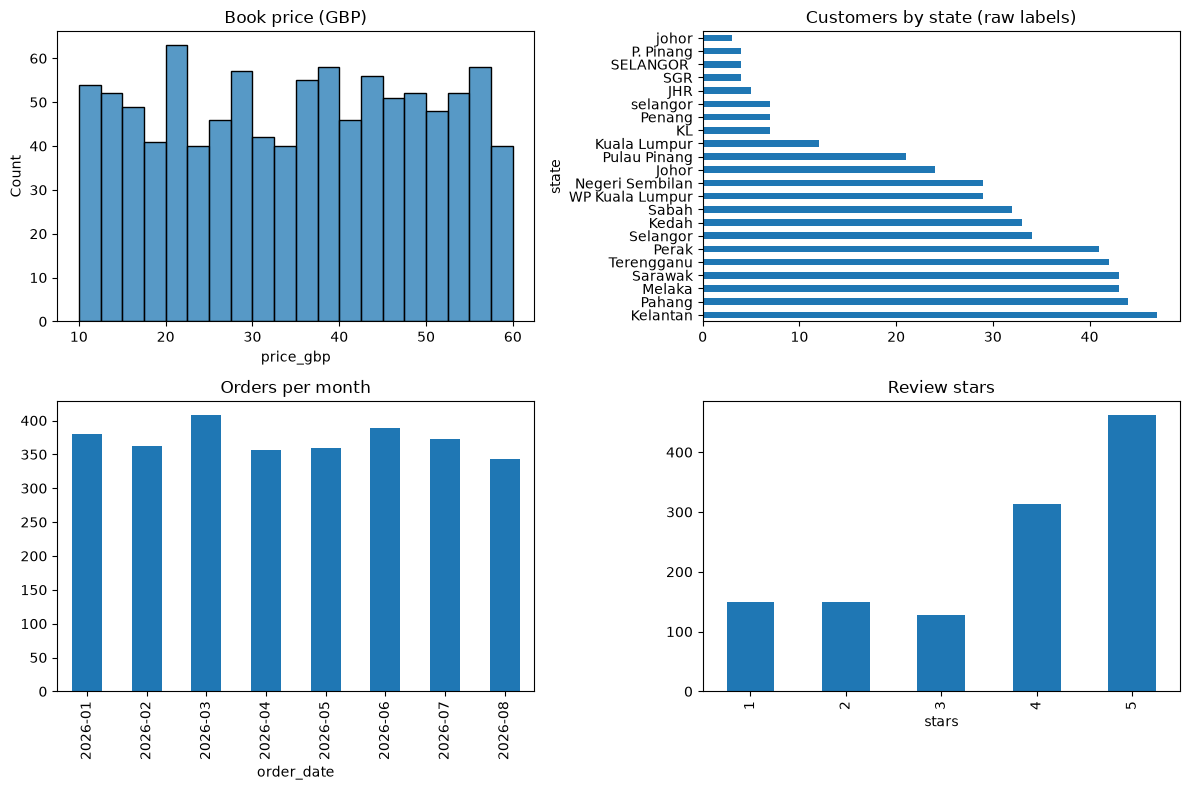

In [8]:
books["price_gbp"] = books["price_raw"].str.replace(
    "£", "", regex=False
).astype(float)

orders_ok = orders.assign(
    order_date=pd.to_datetime(
        orders["order_date"],
        format="%Y-%m-%d",
        errors="coerce"
    )
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(
    books["price_gbp"],
    bins=20,
    ax=axes[0, 0]
).set_title("Book price (GBP)")

customers["state"].value_counts().plot.barh(
    ax=axes[0, 1],
    title="Customers by state (raw labels)"
)

orders_ok.groupby(
    orders_ok["order_date"].dt.to_period("M")
).size().plot.bar(
    ax=axes[1, 0],
    title="Orders per month"
)

reviews["stars"].value_counts().sort_index().plot.bar(
    ax=axes[1, 1],
    title="Review stars"
)

plt.tight_layout()
plt.show()